# 1 · Requirements and the reference aircraft

The design mission and the 737-800 data it is checked against.
Lesson: [01](../docs/lessons/01-requirements-and-reference.md) ·
Theory: [requirements](../docs/requirements.md).

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from acdesign import plotting as P
from acdesign.requirements import B737_800_MISSION as M
from acdesign.units import FT, G0, LB, NMI

P.use_style()
np.set_printoptions(precision=4, suppress=True)
sys.path.insert(0, "../validation")  # cited reference data and the reference aircraft
from reference import b737_800

R = b737_800()

The design mission, in SI and in the units of the airport-planning charts:

In [2]:
print(f"payload {M.payload:,.0f} kg = {M.payload / LB:,.0f} lb")
print(f"range {M.design_range / NMI:,.0f} nmi at Mach {M.cruise_mach}, FL{M.cruise_altitude / FT / 100:.0f}")
print(f"field lengths: take-off {M.takeoff_field_length / FT:,.0f} ft, landing {M.landing_field_length / FT:,.0f} ft")

payload 16,329 kg = 36,000 lb
range 2,800 nmi at Mach 0.78, FL350
field lengths: take-off 7,800 ft, landing 5,800 ft


The transcribed 737-800 data checks itself: the payload-range chart's full-fuel corner must
give back the fuel capacity of the weight table.

In [3]:
fuel_from_chart = R["mtow"] - R["oew_plus_payload_at_full_fuel_mtow"]
print(f"chart: {fuel_from_chart:,.0f} kg, weight table: {R['usable_fuel']:,.0f} kg")
print(f"MZFW - OEW - max payload = {R['mzfw'] - R['oew'] - R['max_structural_payload']:.3f} kg")

chart: 20,820 kg, weight table: 20,893 kg
MZFW - OEW - max payload = -0.000 kg


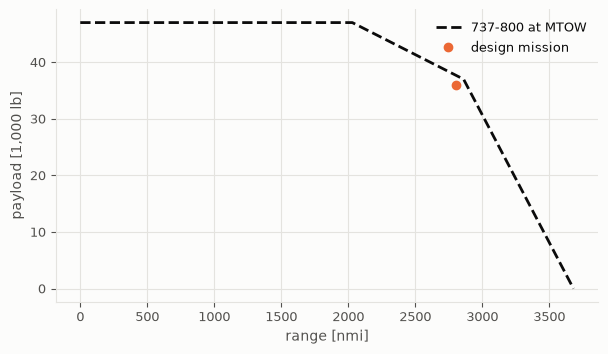

In [4]:
from mission_definition import envelope

x, y = envelope(R)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(x, np.array(y) / 1e3, "--", color=P.REFERENCE, label="737-800 at MTOW")
ax.plot(M.design_range / NMI, M.payload / LB / 1e3, "o", color=P.SERIES[1], label="design mission")
ax.set_xlabel("range [nmi]"); ax.set_ylabel("payload [1,000 lb]"); ax.legend();